# sLTN on ∂LTLf's temporal benchmark

**The problem.** ∂LTLf ("Time to Reason", arXiv 2608.16443) teaches a network to recognise images from labels on whole sequences, through a formula of temporal logic. This notebook runs its main benchmark, *Temporal Multi-Stream*, with sLTN in place of ∂LTLf's logic code. The task, in short:
- A **sequence** has 2 to 10 **steps**. Each step shows three MNIST images, one for each **stream** `x`, `y` and `z`.
- Each image shows a digit **class** from 0 to 7, drawn at random.
- A sequence is labelled **yes** when a fixed formula holds over its steps, **no** otherwise.
- Nothing says which digit an image shows: the network has to learn the 8 classes from the yes/no labels alone.

**The formula.** It is written in LTLf, linear temporal logic on finite sequences. Its operators, read from the current step:
- **G** φ: φ holds at every step from here on.
- **F** φ: φ holds at this step or a later one.
- **X** φ: φ holds at the next step (false at the last step, which has no next one).
- φ **U** ψ: ψ holds at this step or a later one, and φ holds at every step before it.

Below, `x0` means "stream `x` shows a 0". The formula is the conjunction of four rules, from one of two sets:

| | Set 1 | Set 2 |
|---|---|---|
| 1 | G(x0 → F y1): every 0 in `x` is followed, then or later, by a 1 in `y` | (¬y1 U x0) ∨ G ¬y1: `y` shows no 1 before `x` shows a 0 |
| 2 | G((y2 ∨ z3) → ¬F x3): from a 2 in `y` or a 3 in `z` on, `x` never shows a 3 | G(X(y0 ∨ z2) → x3): when the next step has a 0 in `y` or a 2 in `z`, `x` shows a 3 now |
| 3 | G(x4 → X y5): every 4 in `x` is followed at the next step by a 5 in `y` | F x4 → F y5: if `x` ever shows a 4, `y` shows a 5 at some step |
| 4 | G((x6 ∨ y5) → ¬X z7): after a 6 in `x` or a 5 in `y`, `z` doesn't show a 7 at the next step | F(x6 ∨ y4) → ¬F z7: if `x` ever shows a 6 or `y` a 4, `z` never shows a 7 |

**Why this benchmark.** It is ∂LTLf's main benchmark, with published numbers. Before using sLTN on new temporal tasks, it should match ∂LTLf on its own ground. Their tables have four sizes of the task, with 2, 4, 6 and 8 classes (Section 5 explains them); 8 is the hardest, and the one trained here. The labels are not balanced: only 14–22% of the sequences are yes.

**The model.** ∂LTLf's image network, a small CNN, reads one image and gives a probability for each of the 8 classes. sLTN computes the truth value of the formula from these probabilities, and the CNN is trained so that this value matches the label of each sequence (binary cross-entropy). This is what ∂LTLf does with its own logic code; only the logic module changes.

**The comparison.** ∂LTLf's published results with 8 classes, mean of 10 runs: image accuracy 92.7 on both sets, sequence accuracy 96.7 on Set 1 and 98.0 on Set 2.

**What this example shows:**
- **Temporal logic without temporal operators.** G, F, X and U become quantifiers over the steps, with a relation between steps as a guard ("a later step", "the next step"). sLTN has no temporal operator built in (Section 3).
- **Choosing the semantics of the quantifiers.** ∂LTLf's product semantics is defined with small custom quantifiers, and checked against ∂LTLf's own evaluator. Their U needs a different formula, not just a different operator (Section 4).
- **Checking the formulas before training.** With perfect images, every formula must give exactly the labels (Section 5).
- **sLTN as the logic module of an existing pipeline.** ∂LTLf's data, network and training are kept as they are; only the code that computes the formula changes (Section 6).
- **Sequences of different lengths, padded.** Padded steps get images on which the network outputs 0 for every class, so they change nothing in the formula (Section 6).

**Compute.** Section 6 trains one run: about 1 minute on a GPU, about 12 minutes on a CPU. The 10-run and 5 × 5 experiments (Sections 7 and 8) took about an hour on an A40 GPU, with runs in parallel; their results are embedded in the notebook.

In [1]:
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset, random_split
from torchvision import datasets, transforms

import sltn
from sltn import Interpretation, Logic, Signature
from sltn.interpretation.operators.base import AggregationOperator

K, C = 4, 8                            # 4 rules, 8 classes
MAX_LEN = 10                           # the longest sequence
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = "../datasets/"
PUBLISHED = {"set1": (92.7, 96.7), "set2": (92.7, 98.0)}   # ∂LTLf, 8 classes, mean of 10 runs: (image acc, sequence acc)
COLORS = {"sltn": "#eb6834", "published": "#5f5e5a", "grid": "#e7e6e1"}
print("sltn:", sltn.__version__, "| device:", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

sltn: 0.1.0 | device: CPU


## 1. The data

∂LTLf's generator, rewritten step by step from their code (`their_dataset`):
- 1,000 sequences. For each one, a length from 2 to 10; for each step and stream, a class from 0 to 7 and a random MNIST training image of that class. Everything is drawn with Python's `random`, from the seed of their first run (470).
- Images are resized to 32 × 32 and normalised, as in their code.
- **One dataset for all runs.** Their code stores the dataset in a file whose name has no seed, so all 10 runs, and both sets, use the same sequences. The two sets only label them differently.
- Each run splits the 1,000 sequences 80 / 20 with its own seed: it trains on 800 and is scored on the other 200.

In [2]:
def crisp_label(d, fset, K):
    """The label of one sequence: d [L, 3] holds the classes of x, y, z at each step. The first K rules of fset."""
    L = len(d)
    x, y, z = d[:, 0].tolist(), d[:, 1].tolist(), d[:, 2].tolist()
    ok = []
    if fset == "set1":
        ok.append(all(x[t] != 0 or any(y[u] == 1 for u in range(t, L)) for t in range(L)))
        ok.append(all(not (y[t] == 2 or z[t] == 3) or not any(x[u] == 3 for u in range(t, L)) for t in range(L)))
        ok.append(all(x[t] != 4 or (t + 1 < L and y[t + 1] == 5) for t in range(L)))
        ok.append(all(not (x[t] == 6 or y[t] == 5) or not (t + 1 < L and z[t + 1] == 7) for t in range(L)))
    else:                                                  # set2 and set2_exact (Section 4) have the same labels
        until = any(x[t] == 0 and all(y[u] != 1 for u in range(t)) for t in range(L))
        ok.append(until or all(v != 1 for v in y))
        ok.append(all(not (t + 1 < L and (y[t + 1] == 0 or z[t + 1] == 2)) or x[t] == 3 for t in range(L)))
        ok.append(not any(v == 4 for v in x) or any(v == 5 for v in y))
        ok.append(not any(x[t] == 6 or y[t] == 4 for t in range(L)) or not any(v == 7 for v in z))
    return all(ok[:K])


def set_seed(seed):
    # As their code does.
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def seed_of(K, run):
    # Their seed of run r: 470 to 560 for 8 classes.
    return 50 + 10 + 100 * K + 10 * run


def their_dataset(fset, K, n=1000, lmin=2):
    """Their generator, with the seed of run 1 set just before, as in their code. Sequences are padded to MAX_LEN."""
    C = 2 * K
    set_seed(seed_of(K, 1))
    transform = transforms.Compose([transforms.ToTensor(), transforms.Resize((32, 32), antialias=True),
                                    transforms.Normalize((0.1307,), (0.3081,))])
    mnist = datasets.MNIST(DATA, train=True, download=True)
    pools = [mnist.data[mnist.targets == i] for i in range(C)]
    seqs = torch.zeros(n, MAX_LEN, 3, 1, 32, 32)
    masks = torch.zeros(n, MAX_LEN, dtype=torch.bool)
    labels = torch.zeros(n)
    digits = torch.full((n, MAX_LEN, 3), -1, dtype=torch.long)
    for i in range(n):
        L = random.randint(lmin, MAX_LEN)
        for t in range(L):
            d = [random.randint(0, C - 1) for _ in range(3)]
            digits[i, t] = torch.tensor(d)
            for s in range(3):
                pool = pools[d[s]]
                seqs[i, t, s] = transform(pool[random.randint(0, len(pool) - 1)].numpy())
        masks[i, :L] = True
        labels[i] = float(crisp_label(digits[i, :L], fset, K))
    return seqs, masks, labels, digits

In [3]:
seqs, masks, labels1, digits = their_dataset("set1", K)
lengths = masks.sum(1)
labels2 = torch.tensor([float(crisp_label(digits[i, :lengths[i]], "set2", K)) for i in range(len(lengths))])
data = {"set1": (seqs, masks, labels1, digits), "set2": (seqs, masks, labels2, digits)}
print(f"{len(lengths)} sequences, mean length {lengths.float().mean():.2f}")
print(f"labelled yes: Set 1 {labels1.mean():.1%}, Set 2 {labels2.mean():.1%}")
print("first sequence, (x, y, z) per step:", digits[0, :lengths[0]].tolist())

1000 sequences, mean length 5.97
labelled yes: Set 1 22.1%, Set 2 14.4%
first sequence, (x, y, z) per step: [[5, 2, 2], [1, 6, 6]]


One sequence, with its images: each column is a step, with the streams `x`, `y`, `z` from top to bottom. It is labelled yes under Set 1 and no under Set 2: the two sets label the same sequences differently.

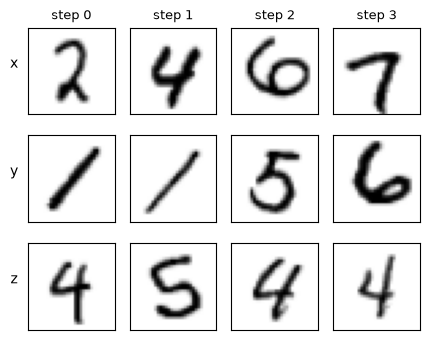

classes (x, y, z) per step: [[2, 1, 4], [4, 1, 5], [6, 5, 4], [7, 6, 4]]
label: Set 1 yes | Set 2 no


In [4]:
k = 720                                # yes under Set 1, no under Set 2
L = int(lengths[k])
fig, axes = plt.subplots(3, L, figsize=(1.1 * L, 3.6))
for t in range(L):
    for r, name in enumerate("xyz"):
        ax = axes[r, t]
        ax.imshow(seqs[k, t, r, 0], cmap="gray_r"); ax.set_xticks([]); ax.set_yticks([])
        if t == 0:
            ax.set_ylabel(name, rotation=0, labelpad=10)
    axes[0, t].set_title(f"step {t}", fontsize=9)
plt.tight_layout(); plt.show()
print("classes (x, y, z) per step:", digits[k, :L].tolist())
print("label: Set 1", "yes" if labels1[k] else "no", "| Set 2", "yes" if labels2[k] else "no")

**Why yes, why no.** The cell below checks each rule on the classes of this sequence, step by step:
- **Set 1 says yes:** every rule holds. Rules 1 and 2 hold because their trigger (a 0 in `x`; a 2 in `y` or a 3 in `z`) never appears. Rules 3 and 4 are triggered and satisfied: the 4 in `x` at step 1 is followed by a 5 in `y` at step 2, and the 6 in `x` and the 5 in `y` at step 2 are not followed by a 7 in `z`.
- **Set 2 says no:** rule 1 fails, and one failed rule is enough. `y` shows a 1 at step 0, so the rule needs `x` to show a 0 before it; `x` never shows a 0. The other three rules hold.

In [5]:
def at(ts):
    return f"step {ts[0]}" if len(ts) == 1 else "steps " + ", ".join(map(str, ts))

def why(d, fset):
    """For each rule of `fset`: (holds, reason) on the classes d [L, 3] of one sequence."""
    L = len(d)
    x, y, z = d[:, 0].tolist(), d[:, 1].tolist(), d[:, 2].tolist()
    steps = lambda cond: [t for t in range(L) if cond(t)]
    if fset == "set1":
        t0, bad = steps(lambda t: x[t] == 0), steps(lambda t: x[t] == 0 and 1 not in y[t:])
        r1 = ((False, f"x shows a 0 at step {bad[0]}, and y shows no 1 from then on") if bad else
              (True, f"each 0 in x ({at(t0)}) is followed by a 1 in y") if t0 else (True, "x never shows a 0"))
        trig = steps(lambda t: y[t] == 2 or z[t] == 3)
        bad = [u for u in range(trig[0], L) if x[u] == 3] if trig else []
        r2 = ((False, f"y2 or z3 at step {trig[0]}, and x shows a 3 at step {bad[0]}") if bad else
              (True, f"y2 or z3 from step {trig[0]}, and x shows no 3 from then on") if trig else
              (True, "y never shows a 2, z never a 3"))
        t4 = steps(lambda t: x[t] == 4)
        bad = [t for t in t4 if not (t + 1 < L and y[t + 1] == 5)]
        r3 = ((False, f"x shows a 4 at step {bad[0]}, and y shows no 5 at the next step") if bad else
              (True, f"each 4 in x ({at(t4)}) has a 5 in y at the next step") if t4 else (True, "x never shows a 4"))
        trig = steps(lambda t: x[t] == 6 or y[t] == 5)
        bad = [t for t in trig if t + 1 < L and z[t + 1] == 7]
        r4 = ((False, f"x6 or y5 at step {bad[0]}, and z shows a 7 at step {bad[0] + 1}") if bad else
              (True, f"x6 or y5 at {at(trig)}, and z shows no 7 at the step after") if trig else
              (True, "x never shows a 6, y never a 5"))
    else:
        t0, t1 = steps(lambda t: x[t] == 0), steps(lambda t: y[t] == 1)
        r1 = ((True, "y never shows a 1") if not t1 else
              (True, f"x shows a 0 at step {t0[0]}, and y shows no 1 before it") if t0 and t1[0] >= t0[0] else
              (False, f"y shows a 1 at step {t1[0]}, before any 0 in x") if t0 else
              (False, f"y shows a 1 at step {t1[0]}, and x never shows a 0"))
        trig = steps(lambda t: t + 1 < L and (y[t + 1] == 0 or z[t + 1] == 2))
        bad = [t for t in trig if x[t] != 3]
        r2 = ((False, f"y0 or z2 at step {bad[0] + 1}, but x shows a {x[bad[0]]}, not a 3, at step {bad[0]}") if bad else
              (True, f"x shows a 3 at each step before a y0 or z2 ({at(trig)})") if trig else
              (True, "y never shows a 0, z never a 2, after the first step"))
        t4, t5 = steps(lambda t: x[t] == 4), steps(lambda t: y[t] == 5)
        r3 = ((True, "x never shows a 4") if not t4 else
              (True, f"x shows a 4 (step {t4[0]}), and y a 5 (step {t5[0]})") if t5 else
              (False, f"x shows a 4 at step {t4[0]}, and y never shows a 5"))
        trig, t7 = steps(lambda t: x[t] == 6 or y[t] == 4), steps(lambda t: z[t] == 7)
        r4 = ((True, "x never shows a 6, y never a 4") if not trig else
              (True, f"x6 or y4 at step {trig[0]}, and z never shows a 7") if not t7 else
              (False, f"x6 or y4 at step {trig[0]}, and z shows a 7 at step {t7[0]}"))
    return [r1, r2, r3, r4]

d = digits[k, :L]
for fset in ("set1", "set2"):
    rules = why(d, fset)
    assert all(ok for ok, _ in rules) == crisp_label(d, fset, K)
    print(f"Set {fset[-1]}: {'yes' if all(ok for ok, _ in rules) else 'no'}")
    for i, (ok, reason) in enumerate(rules, 1):
        print(f"  rule {i} {'holds' if ok else 'FAILS'}: {reason}")

Set 1: yes
  rule 1 holds: x never shows a 0
  rule 2 holds: y never shows a 2, z never a 3
  rule 3 holds: each 4 in x (step 1) has a 5 in y at the next step
  rule 4 holds: x6 or y5 at step 2, and z shows no 7 at the step after
Set 2: no
  rule 1 FAILS: y shows a 1 at step 0, and x never shows a 0
  rule 2 holds: y never shows a 0, z never a 2, after the first step
  rule 3 holds: x shows a 4 (step 1), and y a 5 (step 2)
  rule 4 holds: x6 or y4 at step 2, and z never shows a 7


## 2. The network

∂LTLf's perception network: two 5 × 5 convolutions (32 and 64 filters) with max pooling, a 1,024-unit layer with dropout 0.5, and a softmax over the 8 classes. sLTN uses it as the function `digit`.

In [6]:
PAD = -100.0          # padded steps are images filled with this value (real images are >= -0.43)


class Perception(nn.Module):
    """∂LTLf's perception network."""

    def __init__(self, C):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 32, 5), nn.ReLU(), nn.MaxPool2d(2),          # 32 -> 28 -> 14
            nn.Conv2d(32, 64, 5), nn.ReLU(), nn.MaxPool2d(2),         # 14 -> 10 -> 5
            nn.Flatten(), nn.Linear(64 * 5 * 5, 1024), nn.ReLU(), nn.Dropout(0.5), nn.Linear(1024, C))

    def forward(self, x):
        return torch.softmax(self.net(x), -1)


class Masked(nn.Module):
    """The network, with an all-zero output on padded images: every proposition is 0 there (Section 6)."""

    def __init__(self, net):
        super().__init__()
        self.net = net

    def forward(self, x):
        valid = (x.flatten(1)[:, 0] > PAD / 2).float().unsqueeze(-1)
        return self.net(x) * valid


print(Perception(C))

Perception(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(5, 5), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1600, out_features=1024, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.5, inplace=False)
    (10): Linear(in_features=1024, out_features=8, bias=True)
  )
)


## 3. sLTN: the signature and the formulas

**One individual per step, holding its three images.** A sequence is a variable `s` over the dimension `T` (the steps); `s[t]` is step `t`, with shape `[3, 1, 32, 32]`. The functions `sx`, `sy`, `sz` pick one of its images, and `digit` gives the class probabilities of an image. `Is(p, c)` is the probability that `p` gives to class `c`, and the constants `k0`, …, `k7` are the 8 classes as one-hot vectors. So "stream `x` shows a 0 at step `t`" is `Is(digit(sx(s[t])), k0)`. (`6_DigitRelationsOverTime` explains why one variable holds the three streams, instead of one variable per stream.)

**Relations between steps.** Three structural relations over `T`, rebuilt for each batch from the length of its sequences:
- `geq(t, t1)`: step `t1` is step `t` or a later one;
- `nxt(t, t1)`: step `t1` is the step right after `t`;
- `before(t1, t)`: step `t1` comes before step `t`.

**The LTLf operators**, as quantifiers over the steps with one of these relations as a guard (`|`):

| LTLf | sLTN | in words |
|---|---|---|
| G φ | `∀ t: φ(t)` | φ at every step |
| F ψ, at step `t` | `∃ t1 \| geq(t, t1): ψ(t1)` | ψ at `t` or a later step |
| X ψ, at step `t` | `∃ t1 \| nxt(t, t1): ψ(t1)` | ψ at the next step; at the last step the guard is empty, so it is false |
| φ U ψ | `∃ t: (ψ(t) ∧ ∀ t1 \| before(t1, t): φ(t1))` | some step has ψ, and every earlier step has φ |

This U is the natural translation, but on soft values it differs from ∂LTLf's; Section 4 explains why, and gives the version of Set 2 that is trained here (`set2_exact`).

The formula is the conjunction of the four rules of a set. Written out (`BLOCKS`):

In [7]:
def P(stream, c, t="t"):
    """Proposition "stream shows class c" at step t."""
    return f"Is(digit(s{stream}(s[{t}])), k{c})"


def F_(psi_t1):      # F psi, at t
    return f"(∃ t1 | geq(t, t1): {psi_t1})"


def X_(psi_t1):      # X psi, at t
    return f"(∃ t1 | nxt(t, t1): {psi_t1})"


def FIRST(psi):      # F psi from the first step, as "the first step where psi holds" (Section 4); psi: step -> str
    return f"(∃ t: ({psi('t')} & (∀ t1 | before(t1, t): ¬{psi('t1')})))"


BLOCKS = {
    "set1": [
        f"(∀ t: ({P('x', 0)} -> {F_(P('y', 1, 't1'))}))",                                    # G(x0 -> F y1)
        f"(∀ t: (({P('y', 2)} ∨ {P('z', 3)}) -> ¬{F_(P('x', 3, 't1'))}))",                    # G((y2 | z3) -> !F x3)
        f"(∀ t: ({P('x', 4)} -> {X_(P('y', 5, 't1'))}))",                                     # G(x4 -> X y5)
        f"(∀ t: (({P('x', 6)} ∨ {P('y', 5)}) -> ¬{X_(P('z', 7, 't1'))}))",                    # G((x6 | y5) -> !X z7)
    ],
    "set2": [
        f"((∃ t: ({P('x', 0)} & (∀ t1 | before(t1, t): ¬{P('y', 1, 't1')}))) ∨ (∀ t: ¬{P('y', 1)}))",  # (!y1 U x0) | G !y1
        f"(∀ t: ({X_('(' + P('y', 0, 't1') + ' ∨ ' + P('z', 2, 't1') + ')')} -> {P('x', 3)}))",       # G(X(y0 | z2) -> x3)
        f"((∃ t: {P('x', 4)}) -> (∃ t: {P('y', 5)}))",                                        # F x4 -> F y5
        f"((∃ t: ({P('x', 6)} ∨ {P('y', 4)})) -> ¬(∃ t: {P('z', 7)}))",                       # F(x6 | y4) -> !F z7
    ],
    "set2_exact": [   # Set 2 with ∂LTLf's soft values, under ∃ over the steps = plain sum (Section 4)
        f"((∃ t: ({P('x', 0)} & (∀ t1 | before(t1, t): (¬{P('y', 1, 't1')} & ¬{P('x', 0, 't1')})))) ∨ (∀ t: ¬{P('y', 1)}))",
        f"(∀ t: ({X_('(' + P('y', 0, 't1') + ' ∨ ' + P('z', 2, 't1') + ')')} -> {P('x', 3)}))",
        f"({FIRST(lambda t: P('x', 4, t))} -> {FIRST(lambda t: P('y', 5, t))})",
        f"({FIRST(lambda t: '(' + P('x', 6, t) + ' ∨ ' + P('y', 4, t) + ')')} -> ¬{FIRST(lambda t: P('z', 7, t))})",
    ],
}


def make_signature(fset, K):
    C = 2 * K
    sig = Signature(f"dltlf_{fset}_{C}")
    for sort in ("Step", "Image", "Class", "Probs"):
        sig.sort(sort)
    sig.dimension("T")
    sig.structural_variable("t", "T")
    sig.variable("s", "Step", dims=["T"])
    for f in ("sx", "sy", "sz"):
        sig.function(f, ["Step"], "Image")
    sig.function("digit", ["Image"], "Probs")
    sig.predicate("Is", ["Probs", "Class"])
    for c in range(C):
        sig.constant(f"k{c}", "Class")
    for r in ("geq", "nxt", "before"):
        sig.structural_relation(r, ["T", "T"])
    formula = sig.parse(" & ".join(BLOCKS[fset][:K]))
    return sig, formula

In [8]:
for fset in ("set1", "set2", "set2_exact"):
    print(f"{fset}:")
    for i, block in enumerate(BLOCKS[fset], 1):
        print(f"  {i}. {block}")

set1:
  1. (∀ t: (Is(digit(sx(s[t])), k0) -> (∃ t1 | geq(t, t1): Is(digit(sy(s[t1])), k1))))
  2. (∀ t: ((Is(digit(sy(s[t])), k2) ∨ Is(digit(sz(s[t])), k3)) -> ¬(∃ t1 | geq(t, t1): Is(digit(sx(s[t1])), k3))))
  3. (∀ t: (Is(digit(sx(s[t])), k4) -> (∃ t1 | nxt(t, t1): Is(digit(sy(s[t1])), k5))))
  4. (∀ t: ((Is(digit(sx(s[t])), k6) ∨ Is(digit(sy(s[t])), k5)) -> ¬(∃ t1 | nxt(t, t1): Is(digit(sz(s[t1])), k7))))
set2:
  1. ((∃ t: (Is(digit(sx(s[t])), k0) & (∀ t1 | before(t1, t): ¬Is(digit(sy(s[t1])), k1)))) ∨ (∀ t: ¬Is(digit(sy(s[t])), k1)))
  2. (∀ t: ((∃ t1 | nxt(t, t1): (Is(digit(sy(s[t1])), k0) ∨ Is(digit(sz(s[t1])), k2))) -> Is(digit(sx(s[t])), k3)))
  3. ((∃ t: Is(digit(sx(s[t])), k4)) -> (∃ t: Is(digit(sy(s[t])), k5)))
  4. ((∃ t: (Is(digit(sx(s[t])), k6) ∨ Is(digit(sy(s[t])), k4))) -> ¬(∃ t: Is(digit(sz(s[t])), k7)))
set2_exact:
  1. ((∃ t: (Is(digit(sx(s[t])), k0) & (∀ t1 | before(t1, t): (¬Is(digit(sy(s[t1])), k1) & ¬Is(digit(sx(s[t1])), k0))))) ∨ (∀ t: ¬Is(digit(sy(s[t])), k1)))

## 4. Product semantics

∂LTLf's results are with product semantics: ∧ is the product, ∀ over the steps is the product (one false step makes G false), and ∃ over the steps is the probabilistic sum 1 − ∏(1 − x), so that F passes its gradient to every later step. sLTN doesn't ship these quantifiers; they are defined below as subclasses of `AggregationOperator`, as `6_DigitRelationsOverTime` does, with plain products and no clamping, as in ∂LTLf's code. The other operators are sLTN's defaults: product ∧, ¬x = 1 − x, Reichenbach → (1 − a + a·b).

**Why the U of Section 3 differs.** ∂LTLf computes φ U ψ with a backward recursion over the steps: U(t) = ψ(t) ⊕ φ(t)·U(t+1), where a ⊕ b = a + b − ab. The U of Section 3 is instead a probabilistic sum over the steps that could be the witness. The two agree on true/false values, not on soft ones. Over three steps:
- ∂LTLf: 1 − (1 − ψ₀)(1 − φ₀·(ψ₁ ⊕ φ₁ψ₂)): φ₀ appears once.
- Section 3: 1 − (1 − ψ₀)(1 − φ₀ψ₁)(1 − φ₀φ₁ψ₂): φ₀ appears in two factors.

The probabilistic sum treats its terms as independent, but here they share the φ's, so the same φ is counted more than once, and the value is never below ∂LTLf's.

**The exact U.** Unrolled, their recursion is a sum over the *first* step where ψ holds: Σₜ ψ(t) · ∏_{t1 < t} φ(t1)(1 − ψ(t1)). At most one step is the first one, so a plain sum stays at most 1. In sLTN this is

`∃ t: (ψ(t) ∧ ∀ t1 | before(t1, t): (φ(t1) ∧ ¬ψ(t1)))`

with ∃ over the steps as a plain sum (`AggregSum`). sLTN chooses the operator of a quantifier per dimension, not per quantifier, so the sum applies to every ∃ over the steps in the formula. The other ∃'s of Set 2 are rewritten so that they keep their values under it:
- **F ψ, from the first step**, becomes "the first step where ψ holds", `∃ t: (ψ(t) ∧ ∀ t1 | before(t1, t): ¬ψ(t1))` (`FIRST`, Section 3). Its sum Σₜ ψ(t) · ∏_{t1 < t} (1 − ψ(t1)) equals 1 − ∏ₜ (1 − ψ(t)), the probabilistic sum, exactly.
- **X ψ** has a single next step, so the sum and the probabilistic sum are the same.

This version of Set 2 is `set2_exact`, printed above; `set2` keeps the U of Section 3. Both give the same labels.

**Checked against ∂LTLf's evaluator.** `their_value` rewrites ∂LTLf's evaluator from their code: G, F and X as products and probabilistic sums over the steps, U as their recursion. The cell below compares it with sLTN's value of the formula on random soft class probabilities, 200 sequences of each length from 2 to 10, for rule 1 alone and for the four rules:

In [9]:
def _dims(x, dim):
    return tuple(range(x.dim())) if dim is None else (tuple(dim) if isinstance(dim, (tuple, list)) else (dim,))


class AggregProd(AggregationOperator):
    """∀ as a plain product, as their G. Masked-out entries count as 1."""

    def __call__(self, xs, dim=None, keepdim=False, mask=None):
        x = xs if mask is None else 1 - mask * (1 - xs)
        for d in sorted(_dims(x, dim), reverse=True):
            x = x.prod(dim=d, keepdim=keepdim)
        return x

    def __repr__(self):
        return "AggregProd()"



class AggregProbSum(AggregationOperator):
    """∃ as a plain probabilistic sum 1 - ∏(1 - x), as their F. Masked-out entries count as 0."""

    def __call__(self, xs, dim=None, keepdim=False, mask=None):
        x = 1 - (xs if mask is None else mask * xs)
        for d in sorted(_dims(x, dim), reverse=True):
            x = x.prod(dim=d, keepdim=keepdim)
        return 1 - x

    def __repr__(self):
        return "AggregProbSum()"



class AggregSum(AggregationOperator):
    """∃ as a plain sum, for set2_exact: each ∃ there sums terms of which at most one is true, so it stays <= 1
    (clamped at 1 only for the ~1e-6 rounding of sLTN's stable connectives). Masked-out entries count as 0."""

    def __call__(self, xs, dim=None, keepdim=False, mask=None):
        x = xs if mask is None else mask * xs
        return x.sum(dim=_dims(x, dim), keepdim=keepdim).clamp(max=1)

    def __repr__(self):
        return "AggregSum()"


def make_interp(sig, C, net, fset):
    lg = Logic().with_defaults()
    lg["forall,t"] = AggregProd()
    lg["exists,t"] = AggregSum() if fset == "set2_exact" else AggregProbSum()
    it = Interpretation(sig, logic=lg)
    it["Step"] = sltn.Type("step", shape=(3, 1, 32, 32))
    it["Image"] = sltn.Type("image", shape=(1, 32, 32))
    it["Class"] = sltn.Type("class", shape=(C,))
    it["Probs"] = sltn.Type("probs", shape=(C,))
    it["sx"], it["sy"], it["sz"] = (lambda v: v[:, 0]), (lambda v: v[:, 1]), (lambda v: v[:, 2])
    it["digit"] = net
    it["Is"] = lambda p, c: (p * c).sum(-1, keepdim=True)
    eye = torch.eye(C, device=DEVICE)
    for c in range(C):
        it[f"k{c}"] = eye[c]
    return it


def value(it, formula, imgs):
    """The formula's value on a batch of sequences imgs [B, L, 3, 1, 32, 32]: the relations are rebuilt for L."""
    L = imgs.shape[1]
    it["s"] = imgs
    t = torch.arange(L, device=DEVICE)
    it["geq"] = (t[:, None] <= t[None]).float()                      # geq(t, t1): t1 >= t
    it["nxt"] = (t[:, None] + 1 == t[None]).float()                  # nxt(t, t1): t1 = t + 1
    it["before"] = (t[:, None] < t[None]).float()                    # before(t1, t): t1 < t
    r = it(formula)
    assert r.axis_names[0] == "s"
    return r.value.squeeze(-1)

In [10]:
def their_value(p, fset, K):
    """∂LTLf's product-semantics evaluator, rewritten from their code: p [B, L, 3, C] class probabilities of the
    streams x, y, z. G is the product over the steps, F the probabilistic sum over this step and the later ones,
    X the value at the next step (0 at the last), and U their backward recursion U(t) = psi(t) ⊕ phi(t)·U(t+1)."""
    And, Or, Not, Imp = (lambda a, b: a * b), (lambda a, b: a + b - a * b), (lambda a: 1 - a), (lambda a, b: 1 - a + a * b)
    s = lambda stream, c: p[:, :, "xyz".index(stream), c]                         # [B, L]
    G = lambda v: v.prod(1)
    F_at = lambda v: 1 - (1 - v).flip(1).cumprod(1).flip(1)                        # F at every step, [B, L]
    X_at = lambda v: torch.cat([v[:, 1:], torch.zeros_like(v[:, :1])], 1)

    def U(phi, psi):
        u = torch.zeros_like(psi[:, 0])
        for t in reversed(range(psi.shape[1])):
            u = Or(psi[:, t], phi[:, t] * u)
        return u

    if fset == "set1":
        rules = [lambda: G(Imp(s("x", 0), F_at(s("y", 1)))),
                 lambda: G(Imp(Or(s("y", 2), s("z", 3)), Not(F_at(s("x", 3))))),
                 lambda: G(Imp(s("x", 4), X_at(s("y", 5)))),
                 lambda: G(Imp(Or(s("x", 6), s("y", 5)), Not(X_at(s("z", 7)))))]
    else:
        rules = [lambda: Or(U(Not(s("y", 1)), s("x", 0)), G(Not(s("y", 1)))),
                 lambda: G(Imp(X_at(Or(s("y", 0), s("z", 2))), s("x", 3))),
                 lambda: Imp(F_at(s("x", 4))[:, 0], F_at(s("y", 5))[:, 0]),
                 lambda: Imp(F_at(Or(s("x", 6), s("y", 4)))[:, 0], Not(F_at(s("z", 7))[:, 0]))]
    out = rules[0]()
    for rule in rules[1:K]:
        out = out * rule()
    return out


def compare_with_theirs(fset, K, n=200, seed=0):
    """sLTN's value of the formula against their_value, on random soft class probabilities, for lengths 2 to 10.
    Returns the max and mean absolute difference."""
    C = 2 * K
    g = torch.Generator().manual_seed(seed)
    sig, formula = make_signature(fset, K)
    diffs = []
    for L in range(2, MAX_LEN + 1):
        probs = torch.softmax(3 * torch.randn(n * L * 3, C, generator=g), -1)    # one row per image
        table = probs.to(DEVICE)
        it = make_interp(sig, C, lambda v: table[v[:, 0, 0, 0].long()], fset)    # an "image" carries its row
        imgs = torch.arange(n * L * 3, dtype=torch.float).view(n, L, 3, 1, 1, 1).expand(n, L, 3, 1, 32, 32)
        ours = value(it, formula, imgs.contiguous().to(DEVICE)).cpu()
        diffs.append(ours - their_value(probs.view(n, L, 3, C).double(), fset, K).float())
    d = torch.cat(diffs)
    return d.abs().max().item(), d.abs().mean().item()

In [11]:
for fset in ("set1", "set2", "set2_exact"):
    for k in (1, K):
        mx, mean = compare_with_theirs(fset, k)
        rules = "rule 1 only" if k == 1 else "all 4 rules"
        print(f"{fset:10s} {rules}: |sLTN − ∂LTLf| max {mx:.1e}, mean {mean:.1e}")

set1       rule 1 only: |sLTN − ∂LTLf| max 7.6e-06, mean 2.0e-06


set1       all 4 rules: |sLTN − ∂LTLf| max 1.1e-05, mean 1.7e-06


set2       rule 1 only: |sLTN − ∂LTLf| max 4.3e-01, mean 1.2e-02


set2       all 4 rules: |sLTN − ∂LTLf| max 4.3e-02, mean 4.3e-04
set2_exact rule 1 only: |sLTN − ∂LTLf| max 8.9e-06, mean 2.7e-06


set2_exact all 4 rules: |sLTN − ∂LTLf| max 1.1e-05, mean 1.2e-06


Set 1 and `set2_exact` give ∂LTLf's values, up to 1e-5 (the `eps` of sLTN's stable connectives). `set2` differs only through U: by up to 0.43 on rule 1 alone, and by up to 0.04 on the four rules, where the product with the other rules shrinks the gap. Sections 6 and 7 train `set2_exact`, so that on both sets only the code that computes the formula changes, not its values.

## 5. Sanity check: with perfect images, the formulas give the labels

Before training: if `digit` were perfect, would the formula answer every sequence correctly? Here each "image" carries its class, `digit` returns the one-hot vector of that class, and the formula's value (yes when above 0.5) is compared with the label, on 300 random sequences.

**The four sizes of the task.** ∂LTLf's tables have four sizes. Each rule uses two digits of its own (rule 1 the digits 0 and 1, rule 2 the digits 2 and 3, …), so a size is a number of rules and the digits they use:
- **2 classes:** the images show only 0 and 1, and the formula is rule 1 alone;
- **4 classes:** digits 0–3, rules 1 and 2;
- **6 classes:** digits 0–5, rules 1 to 3;
- **8 classes:** digits 0–7, all four rules, the size trained in this notebook.

The check is cheap, so it covers every size, for both sets and `set2_exact`.

In [12]:
def oracle_check(fset, K, n=300):
    """With perfect perception, the formula must give the labels: (sequences right, n, share labelled yes)."""
    C = 2 * K
    g = torch.Generator().manual_seed(0)
    lengths = torch.randint(2, 11, (n,), generator=g)
    digits = torch.randint(0, C, (n, 10, 3), generator=g)
    labels = torch.tensor([crisp_label(digits[i, :lengths[i]], fset, K) for i in range(n)])
    sig, formula = make_signature(fset, K)
    oracle = lambda v: F.one_hot(v[:, 0, 0, 0].round().long(), C).float()   # an "image" carries its class
    it = make_interp(sig, C, oracle, fset)
    ok = 0
    for L in lengths.unique().tolist():
        idx = torch.nonzero(lengths == L).flatten()
        imgs = torch.zeros(len(idx), L, 3, 1, 32, 32)
        imgs[..., 0, 0, 0] = digits[idx, :L].float()
        ok += ((value(it, formula, imgs.to(DEVICE)) >= 0.5) == labels[idx].to(DEVICE)).sum().item()
    return ok, n, labels.float().mean().item()

In [13]:
for fset in ("set1", "set2", "set2_exact"):
    for k in (1, 2, 3, 4):
        ok, n, pos = oracle_check(fset, k)
        print(f"{fset}, {2 * k} classes: formula = label on {ok}/{n} sequences (labelled yes: {pos:.0%})")

set1, 2 classes: formula = label on 300/300 sequences (labelled yes: 70%)
set1, 4 classes: formula = label on 300/300 sequences (labelled yes: 22%)
set1, 6 classes: formula = label on 300/300 sequences (labelled yes: 12%)


set1, 8 classes: formula = label on 300/300 sequences (labelled yes: 19%)


set2, 2 classes: formula = label on 300/300 sequences (labelled yes: 67%)
set2, 4 classes: formula = label on 300/300 sequences (labelled yes: 12%)
set2, 6 classes: formula = label on 300/300 sequences (labelled yes: 13%)


set2, 8 classes: formula = label on 300/300 sequences (labelled yes: 13%)


set2_exact, 2 classes: formula = label on 300/300 sequences (labelled yes: 67%)
set2_exact, 4 classes: formula = label on 300/300 sequences (labelled yes: 12%)
set2_exact, 6 classes: formula = label on 300/300 sequences (labelled yes: 13%)


set2_exact, 8 classes: formula = label on 300/300 sequences (labelled yes: 13%)


## 6. Training under ∂LTLf's protocol

`run` follows their training code step by step:
- **The seed of run r** is 50 + 10 + 100·4 + 10·r (470 to 560); it seeds Python, NumPy and PyTorch, as their code does.
- **The split** of the 1,000 sequences into 800 / 200 uses that seed. The CNN is built right after it, so it starts from their initial weights.
- **Batches:** 64 sequences of mixed lengths, padded to 10 steps. On padded steps the CNN outputs 0 for every class (`Masked`, Section 2), so the padding changes nothing in the formula, as their masks do.
- **Training:** Adam, learning rate 1e-4, 50 epochs, binary cross-entropy between the formula's value and the label.
- **Scores**, after the last epoch, on the 200 held-out sequences: **image accuracy**, the CNN's most likely class against the true class, over every image of every step; **sequence accuracy**, the formula's value (yes when above 0.5) against the label.

One run, Set 2 (`set2_exact`), run 1:

In [14]:
def run(fset, K, r, data, epochs=50, lr=1e-4, batch=64):
    """Run r of their protocol: their seed, split, initial weights, batches, optimiser and metrics."""
    C = 2 * K
    seed = seed_of(K, r)
    set_seed(seed)
    full = TensorDataset(*data)
    n_tr = int(0.8 * len(full))
    train_ds, val_ds = random_split(full, [n_tr, len(full) - n_tr], generator=torch.Generator().manual_seed(seed))
    train_loader = DataLoader(train_ds, batch_size=batch, shuffle=True)
    val_loader = DataLoader(val_ds, batch_size=batch, shuffle=False)
    sig, formula = make_signature(fset, K)
    net = Perception(C).to(DEVICE)                            # built right after the split: their initial weights
    it = make_interp(sig, C, Masked(net), fset).to(DEVICE)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    t0 = time.perf_counter()

    def padded(imgs, masks):
        return torch.where(masks[:, :, None, None, None, None], imgs, torch.full_like(imgs, PAD))

    for _ in range(epochs):
        net.train()
        for imgs, masks, lab, _ in train_loader:
            imgs, masks, lab = imgs.to(DEVICE), masks.to(DEVICE), lab.to(DEVICE)
            opt.zero_grad()
            F.binary_cross_entropy(value(it, formula, padded(imgs, masks)), lab).backward()
            opt.step()
    net.eval()
    ok_img = n_img = ok_seq = n_seq = 0
    with torch.no_grad():
        for imgs, masks, lab, d in val_loader:
            imgs, masks, lab, d = imgs.to(DEVICE), masks.to(DEVICE), lab.to(DEVICE), d.to(DEVICE)
            pred = net(imgs.flatten(0, 2)).argmax(-1).view(d.shape)
            active = masks[:, :, None].expand_as(d)
            ok_img += (pred == d)[active].sum().item(); n_img += active.sum().item()
            ok_seq += ((value(it, formula, padded(imgs, masks)) > 0.5) == lab.bool()).sum().item(); n_seq += len(lab)
    return dict(img_acc=100 * ok_img / n_img, seq_acc=100 * ok_seq / n_seq, seconds=round(time.perf_counter() - t0, 1))

In [15]:
res = run("set2_exact", K, 1, data["set2"])
print(f"Set 2, run 1: image acc {res['img_acc']:.1f}, sequence acc {res['seq_acc']:.1f} ({res['seconds']:.0f} s)")

Set 2, run 1: image acc 93.4, sequence acc 98.0 (751 s)


The same run on the A40 GPU gave 92.9 and 98.0 (Section 7). Runs on different hardware aren't bit-identical: dropout and the order of floating-point sums differ.

## 7. Results under ∂LTLf's protocol

The 10 runs of each set, as in their tables, run beforehand with `run` on an A40 GPU (about 1 minute per run). Set 2 is `set2_exact`; the last row is Set 2 with the U of Section 3 (`set2`), for comparison.

In [16]:
THEIR_PROTOCOL = {   # (run, image acc, sequence acc), A40 GPU
    "set1": [(1, 92.89, 97.00), (2, 90.83, 96.00), (3, 91.19, 96.00), (4, 93.10, 97.00), (5, 78.29, 93.50), (6, 92.66, 96.00), (7, 93.02, 97.00), (8, 91.85, 94.50), (9, 91.01, 93.50), (10, 48.84, 83.50)],
    "set2_exact": [(1, 92.89, 98.00), (2, 91.82, 97.00), (3, 92.91, 98.00), (4, 92.85, 98.00), (5, 91.98, 96.00), (6, 92.57, 96.00), (7, 93.60, 97.00), (8, 93.06, 98.50), (9, 90.79, 96.00), (10, 91.90, 98.50)],
    "set2 (U of Section 3)": [(1, 91.96, 98.00), (2, 91.74, 96.50), (3, 93.32, 97.00), (4, 93.13, 99.00), (5, 91.47, 96.00), (6, 92.57, 96.00), (7, 92.78, 96.50), (8, 92.58, 99.50), (9, 91.80, 97.50), (10, 91.10, 97.50)],
}

rows_of = {k: [dict(run=r, img_acc=i, seq_acc=s) for r, i, s in v] for k, v in THEIR_PROTOCOL.items()}
theirs = {k: rows_of[k] for k in ("set1", "set2_exact")}
print(f"{'':21s} | {'sLTN image acc':>26s} | {'∂LTLf':>5s} | {'sLTN sequence acc':>17s} | {'∂LTLf':>5s} | runs below 85")
for fset, rows in rows_of.items():
    img, seq = np.array([r["img_acc"] for r in rows]), np.array([r["seq_acc"] for r in rows])
    pub = PUBLISHED[fset[:4]]
    print(f"{fset:21s} | {img.mean():5.1f} ± {img.std():4.1f} (median {np.median(img):4.1f}) | {pub[0]:5.1f} | "
          f"{seq.mean():8.1f} ± {seq.std():3.1f} | {pub[1]:5.1f} | {int((img < 85).sum())} / {len(img)}")

                      |             sLTN image acc | ∂LTLf | sLTN sequence acc | ∂LTLf | runs below 85
set1                  |  86.4 ± 13.2 (median 91.5) |  92.7 |     94.4 ± 3.9 |  96.7 | 2 / 10
set2_exact            |  92.4 ±  0.8 (median 92.7) |  92.7 |     97.3 ± 1.0 |  98.0 | 0 / 10
set2 (U of Section 3) |  92.2 ±  0.7 (median 92.3) |  92.7 |     97.3 ± 1.1 |  98.0 | 0 / 10


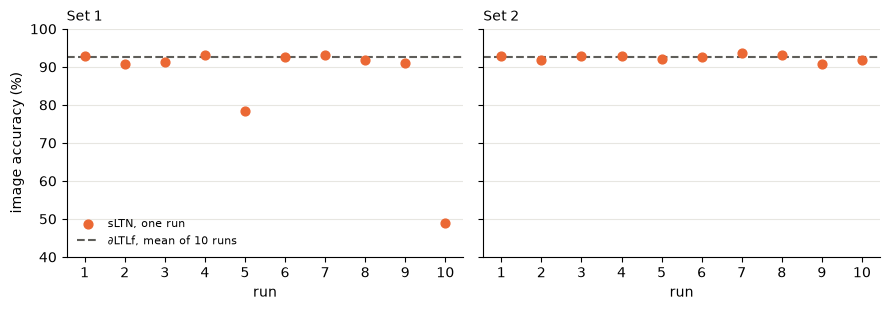

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (fset, rows) in zip(axes, theirs.items()):
    runs = [r["run"] for r in rows]
    ax.scatter(runs, [r["img_acc"] for r in rows], color=COLORS["sltn"], s=40, zorder=3, label="sLTN, one run")
    ax.axhline(PUBLISHED[fset[:4]][0], color=COLORS["published"], lw=1.5, ls="--", label="∂LTLf, mean of 10 runs")
    ax.set_xticks(runs); ax.set_xlabel("run"); ax.set_title(fset[:4].replace("set", "Set "), fontsize=10, loc="left")
    ax.grid(axis="y", color=COLORS["grid"], lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("image accuracy (%)"); axes[0].set_ylim(40, 100)
axes[0].legend(fontsize=8, frameon=False, loc="lower left")
plt.tight_layout(); plt.show()

- **Set 2 is at parity:** every run between 90.8 and 93.6, image accuracy 92.4 against 92.7, sequence accuracy 97.3 against 98.0. With the U of Section 3 the results are the same (92.2 and 97.3): on this benchmark, the difference in soft values doesn't show in the results.
- **Set 1: 8 of 10 runs reach their level** (90.8–93.1), and 2 fail (78.3 and 48.8). Their mean of 92.7 leaves no room for a run at 48.8. So either all their 10 runs succeeded on this dataset, or something still differs; the likeliest candidate is the GPU-level randomness of dropout. Settling it would take running their code.

## 8. How much does the dataset matter?

All ∂LTLf runs share one dataset, so their spread over runs only measures the training seed. To separate the two, an experiment run beforehand on an A40 GPU draws **5 datasets** (dataset seeds 0–4, same generator rules) and trains **5 runs on each** (training seeds 0–4, which set the initial weights and the order of the batches), for both sets: 50 runs. It used an earlier training loop of this example, which differs from Section 6 in two details: batches hold sequences of one length (no padding), and values are clamped away from 0 and 1. Removing the clamps was checked to change no run by more than 2.1 points. The batching changes individual runs, but failures happen under both (Section 7 uses their batching). Set 2 is `set2_exact`; the last line repeats the experiment with the U of Section 3 (`set2`), for comparison.

In [18]:
DATASET_VS_TRAINING = {   # (dataset seed, training seed, image acc, sequence acc, image acc per class), A40 GPU
    "set1": [
        (0, 0, 49.65, 88.0, [12.4, 95.1, 62.1, 72.9, 95.6, 51.6, 0.0, 0.0]),
        (0, 1, 66.75, 91.0, [0.0, 66.6, 84.5, 90.2, 98.9, 42.2, 95.9, 57.2]),
        (0, 2, 38.49, 87.5, [0.0, 0.0, 93.8, 61.9, 97.3, 45.2, 1.1, 0.0]),
        (0, 3, 44.23, 87.0, [0.0, 59.2, 78.2, 83.4, 96.4, 29.0, 0.0, 0.0]),
        (0, 4, 47.18, 87.5, [0.0, 79.7, 87.3, 74.4, 95.8, 31.3, 0.0, 0.0]),
        (1, 0, 94.14, 93.5, [97.8, 97.0, 95.9, 93.3, 97.1, 88.7, 92.2, 91.4]),
        (1, 1, 92.82, 93.0, [96.9, 96.4, 95.0, 92.6, 96.9, 82.9, 89.6, 92.7]),
        (1, 2, 94.91, 94.0, [98.5, 97.6, 95.0, 90.8, 97.8, 94.0, 93.9, 91.6]),
        (1, 3, 93.37, 92.5, [96.9, 97.2, 94.5, 94.9, 97.4, 82.1, 92.7, 92.0]),
        (1, 4, 93.89, 94.0, [97.4, 97.2, 96.1, 92.9, 97.4, 89.1, 89.6, 91.6]),
        (2, 0, 94.33, 97.0, [93.1, 95.7, 90.0, 90.6, 97.3, 97.5, 93.6, 97.3]),
        (2, 1, 94.61, 97.0, [96.0, 97.0, 90.7, 90.8, 96.6, 96.8, 93.1, 96.4]),
        (2, 2, 95.68, 97.5, [98.0, 97.5, 92.4, 92.1, 98.3, 97.0, 94.5, 95.9]),
        (2, 3, 94.28, 96.5, [97.5, 96.5, 89.1, 89.4, 97.5, 97.0, 90.6, 97.1]),
        (2, 4, 94.28, 97.0, [96.4, 96.5, 91.6, 89.4, 97.3, 96.6, 91.1, 95.9]),
        (3, 0, 93.62, 97.0, [95.7, 97.6, 91.3, 88.4, 97.2, 93.6, 91.5, 93.8]),
        (3, 1, 56.7, 92.5, [0.0, 86.9, 85.6, 88.2, 97.7, 64.1, 1.2, 30.5]),
        (3, 2, 77.19, 92.5, [95.1, 98.1, 84.4, 88.2, 97.0, 71.9, 80.0, 0.0]),
        (3, 3, 89.1, 97.5, [93.9, 94.0, 88.7, 88.0, 96.7, 89.4, 91.1, 70.5]),
        (3, 4, 93.76, 98.0, [95.5, 98.1, 90.3, 88.4, 97.7, 93.1, 92.9, 94.2]),
        (4, 0, 92.68, 96.0, [97.0, 97.5, 96.2, 90.9, 96.7, 72.8, 95.8, 94.8]),
        (4, 1, 92.99, 95.0, [95.6, 97.5, 94.1, 90.9, 96.5, 83.8, 93.5, 91.8]),
        (4, 2, 93.04, 95.5, [97.4, 97.5, 95.2, 86.5, 96.3, 81.3, 95.1, 95.5]),
        (4, 3, 91.86, 95.0, [97.0, 98.4, 93.4, 89.2, 96.7, 70.3, 95.1, 95.0]),
        (4, 4, 93.04, 96.0, [96.3, 97.5, 93.4, 90.7, 96.5, 78.9, 96.0, 95.3]),
    ],
    "set2_exact": [
        (0, 0, 94.18, 98.0, [96.0, 98.9, 96.2, 92.1, 98.9, 90.4, 96.6, 83.3]),
        (0, 1, 94.1, 98.5, [96.2, 99.2, 95.2, 87.5, 98.3, 93.4, 96.3, 85.8]),
        (0, 2, 94.74, 98.5, [96.4, 99.2, 95.8, 91.7, 97.9, 92.3, 97.2, 86.7]),
        (0, 3, 93.56, 98.5, [95.4, 99.2, 95.6, 89.1, 99.4, 92.5, 94.3, 81.9]),
        (0, 4, 93.96, 98.0, [96.2, 99.6, 95.8, 88.0, 97.9, 92.3, 95.6, 85.4]),
        (1, 0, 93.23, 97.0, [97.4, 97.9, 96.1, 87.1, 93.8, 94.8, 88.9, 89.4]),
        (1, 1, 92.3, 96.5, [95.9, 97.2, 95.7, 93.1, 91.8, 84.7, 88.7, 91.6]),
        (1, 2, 93.92, 97.5, [97.8, 96.6, 97.3, 90.3, 90.9, 92.2, 92.9, 93.3]),
        (1, 3, 93.65, 95.5, [98.3, 96.4, 94.5, 91.9, 92.9, 88.9, 92.2, 94.1]),
        (1, 4, 93.34, 96.0, [97.8, 97.9, 95.2, 89.9, 95.4, 90.1, 89.6, 90.8]),
        (2, 0, 64.48, 91.5, [94.6, 98.2, 93.8, 56.9, 0.0, 37.5, 95.2, 47.4]),
        (2, 1, 69.89, 90.5, [91.3, 97.0, 95.1, 51.9, 0.0, 84.8, 95.6, 52.6]),
        (2, 2, 92.65, 97.0, [98.9, 98.0, 95.1, 81.7, 91.2, 94.7, 92.9, 90.2]),
        (2, 3, 75.14, 92.5, [95.1, 97.7, 96.0, 40.6, 38.7, 92.4, 95.4, 52.8]),
        (2, 4, 94.08, 98.0, [98.2, 98.0, 92.4, 89.0, 97.7, 96.6, 94.5, 86.8]),
        (3, 0, 95.25, 99.0, [98.7, 98.3, 90.6, 90.4, 97.9, 96.5, 95.3, 94.5]),
        (3, 1, 94.64, 97.0, [98.2, 97.9, 90.3, 87.8, 97.7, 94.6, 97.2, 93.8]),
        (3, 2, 95.72, 98.0, [98.2, 98.1, 92.5, 89.8, 97.9, 97.6, 96.0, 95.9]),
        (3, 3, 94.87, 97.5, [97.8, 97.4, 93.6, 86.4, 98.1, 96.9, 95.3, 93.8]),
        (3, 4, 95.54, 98.0, [98.2, 97.9, 94.6, 89.6, 97.7, 96.2, 96.2, 94.2]),
        (4, 0, 81.45, 94.0, [94.9, 96.8, 89.6, 0.2, 93.2, 89.0, 98.0, 96.0]),
        (4, 1, 93.6, 96.0, [95.4, 97.7, 95.0, 88.4, 90.0, 95.5, 92.9, 95.0]),
        (4, 2, 81.54, 92.5, [95.4, 97.5, 89.6, 0.2, 91.6, 92.6, 97.8, 93.8]),
        (4, 3, 90.32, 96.0, [95.1, 97.9, 93.2, 64.7, 94.1, 91.7, 92.6, 95.3]),
        (4, 4, 92.73, 95.5, [95.8, 98.2, 92.5, 81.6, 89.1, 91.7, 98.2, 96.3]),
    ],
    "set2 (U of Section 3)": [
        (0, 0, 93.99, 98.0, [97.7, 99.6, 95.6, 90.8, 97.3, 91.7, 94.5, 83.8]),
        (0, 1, 94.69, 98.5, [97.3, 98.7, 94.0, 90.2, 98.3, 88.3, 95.9, 94.7]),
        (0, 2, 95.44, 98.5, [96.4, 98.9, 94.4, 92.3, 98.9, 91.0, 95.9, 95.4]),
        (0, 3, 94.2, 99.0, [95.4, 98.9, 92.7, 88.8, 97.7, 86.8, 96.1, 97.5]),
        (0, 4, 93.83, 97.5, [95.4, 98.5, 95.2, 86.9, 96.2, 93.0, 95.4, 89.5]),
        (1, 0, 93.32, 96.0, [97.6, 96.8, 94.5, 90.8, 94.3, 86.8, 92.0, 93.9]),
        (1, 1, 93.18, 97.0, [96.5, 96.2, 96.6, 94.9, 94.5, 88.9, 86.6, 91.4]),
        (1, 2, 93.34, 97.0, [97.8, 96.4, 97.7, 91.0, 93.8, 93.2, 82.8, 93.3]),
        (1, 3, 93.76, 96.5, [98.3, 97.0, 94.7, 87.3, 95.6, 93.6, 91.1, 92.0]),
        (1, 4, 93.54, 96.5, [97.6, 97.6, 94.7, 90.3, 94.0, 90.1, 91.3, 92.4]),
        (2, 0, 69.53, 90.5, [92.4, 94.7, 95.3, 49.4, 0.0, 84.6, 95.2, 53.7]),
        (2, 1, 70.79, 89.5, [93.5, 97.0, 95.3, 50.6, 0.0, 81.1, 96.1, 61.9]),
        (2, 2, 93.63, 98.0, [97.5, 97.0, 94.9, 85.6, 90.3, 96.8, 96.1, 92.1]),
        (2, 3, 93.66, 98.0, [96.9, 98.0, 94.9, 84.4, 92.8, 95.2, 97.2, 91.2]),
        (2, 4, 92.96, 98.5, [96.4, 97.5, 95.3, 84.8, 90.5, 94.9, 96.8, 88.7]),
        (3, 0, 94.67, 98.0, [98.2, 98.1, 86.3, 92.9, 98.4, 96.7, 96.2, 90.4]),
        (3, 1, 94.32, 98.0, [98.2, 97.4, 89.9, 87.3, 97.9, 94.6, 95.3, 94.2]),
        (3, 2, 95.37, 97.0, [98.4, 97.6, 93.2, 86.9, 95.8, 97.2, 96.9, 97.4]),
        (3, 3, 95.34, 99.0, [98.7, 96.7, 92.0, 88.4, 97.9, 96.5, 96.9, 95.9]),
        (3, 4, 94.46, 98.0, [97.3, 98.3, 94.6, 85.6, 97.0, 96.2, 94.8, 92.3]),
        (4, 0, 80.11, 94.0, [93.7, 97.2, 88.0, 1.7, 89.3, 84.7, 99.1, 93.1]),
        (4, 1, 92.26, 96.0, [95.6, 97.7, 89.4, 88.4, 87.7, 89.4, 96.2, 94.8]),
        (4, 2, 78.34, 94.0, [93.3, 98.4, 82.6, 0.0, 91.0, 77.3, 97.8, 92.3]),
        (4, 3, 79.29, 94.0, [94.4, 97.5, 83.9, 0.6, 91.2, 78.7, 99.1, 95.0]),
        (4, 4, 92.31, 95.0, [95.6, 98.2, 91.6, 85.0, 87.3, 88.8, 98.0, 95.5]),
    ],
}
DATASET_STATS = {   # per dataset: (share labelled yes, share of sequences where each rule is triggered)
    "set1": [(0.21, [0.5175, 0.7362, 0.525, 0.76]), (0.2087, [0.4975, 0.7275, 0.5062, 0.725]), (0.2138, [0.52, 0.7512, 0.5325, 0.7362]), (0.22, [0.5487, 0.7638, 0.525, 0.7225]), (0.1975, [0.4938, 0.735, 0.5687, 0.75])],
    "set2_exact": [(0.1513, [0.4988, 0.6613, 0.525, 0.7412]), (0.1575, [0.52, 0.6763, 0.5062, 0.7225]), (0.1625, [0.5487, 0.6512, 0.5325, 0.735]), (0.1462, [0.5413, 0.675, 0.525, 0.7225]), (0.1488, [0.5125, 0.6687, 0.5687, 0.7312])],
}

as_rows = lambda v: [dict(data_seed=d, train_seed=s, img_acc=i, seq_acc=q, img_acc_per_class=pc) for d, s, i, q, pc in v]
grid = {k: as_rows(DATASET_VS_TRAINING[k]) for k in ("set1", "set2_exact")}
old_u = {"set2 (U of Section 3)": as_rows(DATASET_VS_TRAINING["set2 (U of Section 3)"])}
for fset, rows in {**grid, **old_u}.items():
    img = np.array([r["img_acc"] for r in rows])
    per_dataset = [np.array([r["img_acc"] for r in rows if r["data_seed"] == d]) for d in range(5)]
    between = np.var([v.mean() for v in per_dataset])
    within = np.mean([v.var() for v in per_dataset])
    print(f"{fset}: image acc {img.mean():.1f} ± {img.std():.1f} (median {np.median(img):.1f}), "
          f"{int((img >= 85).sum())} / {len(img)} runs above 85")
    print("   mean image acc of each dataset:", ", ".join(f"{v.mean():.1f}" for v in per_dataset))
    print(f"   variance between datasets {between:.0f}, within a dataset {within:.0f}")

set1: image acc 82.5 ± 18.8 (median 93.0), 18 / 25 runs above 85
   mean image acc of each dataset: 49.3, 93.8, 94.6, 82.1, 92.7
   variance between datasets 297, within a dataset 58
set2_exact: image acc 90.0 ± 8.3 (median 93.6), 20 / 25 runs above 85
   mean image acc of each dataset: 94.1, 93.3, 79.2, 95.2, 87.9
   variance between datasets 35, within a dataset 35
set2 (U of Section 3): image acc 90.3 ± 7.6 (median 93.6), 20 / 25 runs above 85
   mean image acc of each dataset: 94.4, 93.4, 84.1, 94.8, 84.5
   variance between datasets 24, within a dataset 34


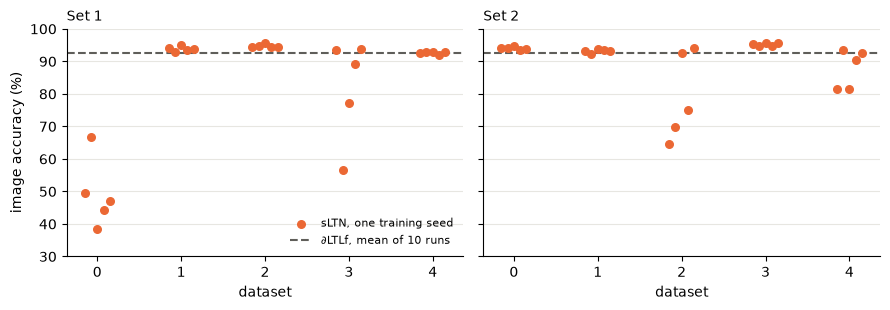

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, (fset, rows) in zip(axes, grid.items()):
    for d in range(5):
        v = [r["img_acc"] for r in rows if r["data_seed"] == d]
        ax.scatter(np.full(len(v), d) + np.linspace(-0.15, 0.15, len(v)), v, color=COLORS["sltn"], s=30, zorder=3,
                   label="sLTN, one training seed" if d == 0 else None)
    ax.axhline(PUBLISHED[fset[:4]][0], color=COLORS["published"], lw=1.5, ls="--", label="∂LTLf, mean of 10 runs")
    ax.set_xticks(range(5)); ax.set_xlabel("dataset"); ax.set_title(fset[:4].replace("set", "Set "), fontsize=10, loc="left")
    ax.grid(axis="y", color=COLORS["grid"], lw=0.8); ax.set_axisbelow(True)
    for sp in ("top", "right"):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel("image accuracy (%)"); axes[0].set_ylim(30, 100)
axes[0].legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

- **On Set 1, the dataset decides.** Dataset 0 fails with every training seed, datasets 1, 2 and 4 succeed with every one. The image accuracy varies 5 times more between datasets than within one.
- **On Set 2 the effect is milder:** two datasets (2 and 4) have failed runs, and the dataset and the training seed weigh about the same. The U of Section 3 gives the same picture: the same two datasets fail, and 20 of 25 runs are above 85.

**How a run fails.** In every failed run, one to three classes are (almost) never predicted. The image accuracy for each class, in the runs below 85:

In [20]:
for fset, rows in grid.items():
    for r in rows:
        if r["img_acc"] < 85:
            per_class = "  ".join(f"{a:5.1f}" for a in r["img_acc_per_class"])
            print(f"{fset} dataset {r['data_seed']} seed {r['train_seed']}: {r['img_acc']:5.1f} | per class {per_class}")

set1 dataset 0 seed 0:  49.6 | per class  12.4   95.1   62.1   72.9   95.6   51.6    0.0    0.0
set1 dataset 0 seed 1:  66.8 | per class   0.0   66.6   84.5   90.2   98.9   42.2   95.9   57.2
set1 dataset 0 seed 2:  38.5 | per class   0.0    0.0   93.8   61.9   97.3   45.2    1.1    0.0
set1 dataset 0 seed 3:  44.2 | per class   0.0   59.2   78.2   83.4   96.4   29.0    0.0    0.0
set1 dataset 0 seed 4:  47.2 | per class   0.0   79.7   87.3   74.4   95.8   31.3    0.0    0.0
set1 dataset 3 seed 1:  56.7 | per class   0.0   86.9   85.6   88.2   97.7   64.1    1.2   30.5
set1 dataset 3 seed 2:  77.2 | per class  95.1   98.1   84.4   88.2   97.0   71.9   80.0    0.0
set2_exact dataset 2 seed 0:  64.5 | per class  94.6   98.2   93.8   56.9    0.0   37.5   95.2   47.4
set2_exact dataset 2 seed 1:  69.9 | per class  91.3   97.0   95.1   51.9    0.0   84.8   95.6   52.6
set2_exact dataset 2 seed 3:  75.1 | per class  95.1   97.7   96.0   40.6   38.7   92.4   95.4   52.8
set2_exact dataset 4 s

- The lost classes depend on the dataset: Set 1's dataset 0 loses classes 0, 6 and 7 in most runs; Set 2's dataset 2 loses class 4, and dataset 4 loses class 3.
- Yet these runs still answer 87–94% of the sequences correctly: most labels can be satisfied without the lost classes.
- **What makes a dataset hard isn't known yet.** The simple statistics are about the same for every dataset: the share of yes labels (19.8–22.0% on Set 1, 14.6–16.2% on Set 2), and how often each rule is triggered (below).

In [21]:
for fset in grid:
    for d, (yes, trig) in enumerate(DATASET_STATS[fset]):
        print(f"{fset} dataset {d}: labelled yes {yes:.1%} | share of sequences where each rule is "
              f"triggered: {', '.join(f'{v:.2f}' for v in trig)}")

set1 dataset 0: labelled yes 21.0% | share of sequences where each rule is triggered: 0.52, 0.74, 0.53, 0.76
set1 dataset 1: labelled yes 20.9% | share of sequences where each rule is triggered: 0.50, 0.73, 0.51, 0.72
set1 dataset 2: labelled yes 21.4% | share of sequences where each rule is triggered: 0.52, 0.75, 0.53, 0.74
set1 dataset 3: labelled yes 22.0% | share of sequences where each rule is triggered: 0.55, 0.76, 0.53, 0.72
set1 dataset 4: labelled yes 19.8% | share of sequences where each rule is triggered: 0.49, 0.73, 0.57, 0.75
set2_exact dataset 0: labelled yes 15.1% | share of sequences where each rule is triggered: 0.50, 0.66, 0.53, 0.74
set2_exact dataset 1: labelled yes 15.8% | share of sequences where each rule is triggered: 0.52, 0.68, 0.51, 0.72
set2_exact dataset 2: labelled yes 16.2% | share of sequences where each rule is triggered: 0.55, 0.65, 0.53, 0.73
set2_exact dataset 3: labelled yes 14.6% | share of sequences where each rule is triggered: 0.54, 0.68, 0.53, 

## 9. Findings

**1. sLTN writes ∂LTLf's temporal logic with its own quantifiers.** G, F, X and U are quantifiers over the steps, guarded by relations between steps; under product semantics they give ∂LTLf's values, and every formula gives the right label on perfect images (Sections 3–5). U is the one operator whose natural translation differs from ∂LTLf's on soft values; written as "the first step where ψ holds", with ∃ as a plain sum, it gives their values exactly (Section 4).

**2. Under ∂LTLf's exact protocol, sLTN matches their results.**
- Set 2: image accuracy 92.4 ± 0.8 against 92.7, sequence accuracy 97.3 ± 1.0 against 98.0. The U of Section 3 gives the same results.
- Set 1: 8 of 10 runs at their level (90.8–93.1); 2 runs fail, so the mean is 86.4 ± 13.2 (median 91.5) against 92.7.

**3. The dataset decides much of the result.** All ∂LTLf runs share one dataset, and their tables report means only. Over 5 datasets × 5 training seeds, Set 1 has one dataset on which every run fails and three on which every run succeeds; its image accuracy varies 5 times more between datasets than between training seeds. On Set 2 the two weigh about the same. A failed run loses one to three classes while still answering most sequences correctly.

**Differences from ∂LTLf that remain:**
- **Hardware:** runs are not bit-identical to theirs (dropout, order of floating-point sums).
- Their code was read, not run.

**Limits:**
- **8 classes only.** Their tables also have 2, 4 and 6 classes; these weren't run under their protocol.
- **Two failures out of 10 on Set 1** under their protocol can't be told apart from bad luck without more runs on their dataset.
- **What makes a dataset hard** is open: the simple statistics don't separate hard datasets from easy ones.